In [1]:
import sys
sys.path.append("../..")

import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib
import os
from surgeNN import io
import gcsfs
fs = gcsfs.GCSFileSystem() #list stores, stripp zarr from filename, load 

In [2]:
from surgeNN import evaluation
p = np.arange(0.1,1.1,.05)
r = np.arange(0.1,1.1,.05)
[P,R] = np.meshgrid(p,r)
f1_contours = evaluation.compute_f1(P,R)

In [3]:
#configure the script
tg        = 'esbjerg-esb-dnk-dmi.csv'#'brest-822a-fra-uhslc.csv'#
max_timesteps_between_extremes = 3

folders = [['/home/jovyan/surgeNN/results/nns/sensitivity_tests/3x3/performance/lstm',
            '/home/jovyan/surgeNN/results/nns/tide/performance/lstm',
            ]]
models = ['lstm']

labels = ['Standard LSTM','With tides as predictor']

model_datasets={}
for m,model in enumerate(models):
    datasets=[]
    for folder in folders[m]:
        dir_name = folder

        ds =io.Output(dir_name)
        ds.open_performance_data([tg])
        ds.data = ds.data.sel(max_timesteps_between_extremes=max_timesteps_between_extremes).load()

        observed_thresholds = ds.observed_thresholds()
        ds = ds.data
        ds['observed_thresholds'] = observed_thresholds
        datasets.append(ds)

    '''
    ds = xr.concat(datasets,dim='test',coords='different')
    ds['test'] = folders[m]
    
    model_datasets[model] = ds
    '''
    
codec = xr.open_dataset('/home/jovyan/surgeNN/results/gtsm/CoDEC_ERA5_at_gesla3_tgs_eu_performance.nc')


where_observed_peaks = (datasets[0].o.isel(it=0)>=observed_thresholds)
if max_timesteps_between_extremes>0:
    where_observed_peaks = ((where_observed_peaks) & (where_observed_peaks.rolling(time=1+2*int(max_timesteps_between_extremes),center='True').sum()>1)) #from 'compute_statistics_on_output_ds'\n",

Text(0.5, 0, 'Relative RMSE [-]')

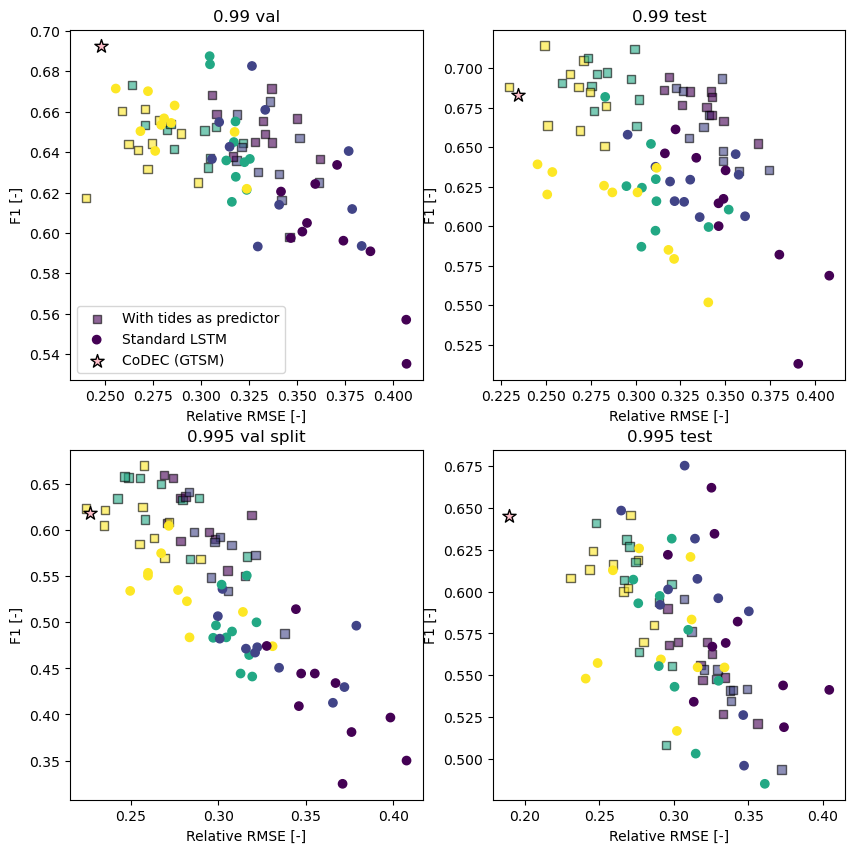

In [4]:
fig = plt.figure(figsize=(10,10))
quantile=.99
split='val'
ax = fig.add_subplot(221)
'''
ax.scatter(datasets[2].rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0)/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
            datasets[2].f1.sel(split=split,quantile=quantile).isel(tg=0),facecolor='red',edgecolor='black',label=labels[2])
'''
ax.scatter(datasets[1].rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0)/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
            datasets[1].f1.sel(split=split,quantile=quantile).isel(tg=0),c=datasets[0].hyperparameters.sel(split=split).isel(tg=0).sel(p='dl_alpha'),marker='s',label=labels[1],zorder=0,edgecolor='black',alpha=.6)

ax.scatter(datasets[0].rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0)/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
            datasets[0].f1.sel(split=split,quantile=quantile).isel(tg=0),c=datasets[0].hyperparameters.sel(split=split).isel(tg=0).sel(p='dl_alpha'),label=labels[0])

ax.scatter(codec.rmse_extremes.sel(split=split,quantile=quantile,tg='esbjerg-esb-dnk-dmi.csv')/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
                                      codec.f1.sel(split=split,quantile=quantile,tg='esbjerg-esb-dnk-dmi.csv'),marker='*',facecolor='pink',edgecolor='black',s=100,label='CoDEC (GTSM)')
ax.set_title(str(quantile) +' '+str(split))
ax.set_ylabel('F1 [-]')
ax.set_xlabel('Relative RMSE [-]')
ax.legend()


quantile=.99
split='test'
ax = fig.add_subplot(222)
'''
ax.scatter(datasets[2].rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0)/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
            datasets[2].f1.sel(split=split,quantile=quantile).isel(tg=0),facecolor='red',edgecolor='black',label=labels[2])
'''
ax.scatter(datasets[1].rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0)/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
            datasets[1].f1.sel(split=split,quantile=quantile).isel(tg=0),c=datasets[0].hyperparameters.sel(split=split).isel(tg=0).sel(p='dl_alpha'),marker='s',label=labels[1],zorder=0,edgecolor='black',alpha=.6)

ax.scatter(datasets[0].rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0)/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
            datasets[0].f1.sel(split=split,quantile=quantile).isel(tg=0),c=datasets[0].hyperparameters.sel(split=split).isel(tg=0).sel(p='dl_alpha'),label=labels[0])

ax.scatter(codec.rmse_extremes.sel(split=split,quantile=quantile,tg='esbjerg-esb-dnk-dmi.csv')/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
                                      codec.f1.sel(split=split,quantile=quantile,tg='esbjerg-esb-dnk-dmi.csv'),marker='*',facecolor='pink',edgecolor='black',s=100,label='CoDEC (GTSM)')
ax.set_title(str(quantile) +' '+str(split))
ax.set_ylabel('F1 [-]')
ax.set_xlabel('Relative RMSE [-]')



quantile=.995
split='val'
ax = fig.add_subplot(223)
'''
ax.scatter(datasets[2].rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0)/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
            datasets[2].f1.sel(split=split,quantile=quantile).isel(tg=0),facecolor='red',edgecolor='black',label=labels[2])
'''
ax.scatter(datasets[1].rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0)/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
            datasets[1].f1.sel(split=split,quantile=quantile).isel(tg=0),c=datasets[0].hyperparameters.sel(split=split).isel(tg=0).sel(p='dl_alpha'),marker='s',label=labels[1],zorder=0,edgecolor='black',alpha=.6)

ax.scatter(datasets[0].rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0)/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
            datasets[0].f1.sel(split=split,quantile=quantile).isel(tg=0),c=datasets[0].hyperparameters.sel(split=split).isel(tg=0).sel(p='dl_alpha'),label=labels[0])

ax.scatter(codec.rmse_extremes.sel(split=split,quantile=quantile,tg='esbjerg-esb-dnk-dmi.csv')/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
                                      codec.f1.sel(split=split,quantile=quantile,tg='esbjerg-esb-dnk-dmi.csv'),marker='*',facecolor='pink',edgecolor='black',s=100,label='CoDEC (GTSM)')
ax.set_title(str(quantile) +' '+str(split)+' split')
ax.set_ylabel('F1 [-]')
ax.set_xlabel('Relative RMSE [-]')


quantile=.995
split='test'
ax = fig.add_subplot(224)
'''
ax.scatter(datasets[2].rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0)/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
            datasets[2].f1.sel(split=split,quantile=quantile).isel(tg=0),facecolor='red',edgecolor='black',label=labels[2])
'''
ax.scatter(datasets[1].rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0)/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
            datasets[1].f1.sel(split=split,quantile=quantile).isel(tg=0),c=datasets[0].hyperparameters.sel(split=split).isel(tg=0).sel(p='dl_alpha'),marker='s',label=labels[1],zorder=0,edgecolor='black',alpha=.6)

ax.scatter(datasets[0].rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0)/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
            datasets[0].f1.sel(split=split,quantile=quantile).isel(tg=0),c=datasets[0].hyperparameters.sel(split=split).isel(tg=0).sel(p='dl_alpha'),label=labels[0])
ax.scatter(codec.rmse_extremes.sel(split=split,quantile=quantile,tg='esbjerg-esb-dnk-dmi.csv')/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
                                      codec.f1.sel(split=split,quantile=quantile,tg='esbjerg-esb-dnk-dmi.csv'),marker='*',facecolor='pink',edgecolor='black',s=100,label='CoDEC (GTSM)')
ax.set_title(str(quantile) +' '+str(split))
ax.set_ylabel('F1 [-]')
ax.set_xlabel('Relative RMSE [-]')

In [25]:
quantile=.995
split='val'
print(np.mean(datasets[0].rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0)/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),axis=0).values)
print(np.mean(datasets[1].rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0)/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),axis=0).values)
print(np.mean(datasets[0].f1.sel(split=split,quantile=quantile).isel(tg=0),axis=0).values)
print(np.mean(datasets[1].f1.sel(split=split,quantile=quantile).isel(tg=0),axis=0).values)

[0.36404727 0.33134347 0.30983653 0.27968396]
[0.28693727 0.30515336 0.26880359 0.25585262]
[0.41731659 0.4726228  0.48953343 0.53448963]
[0.61444192 0.56968685 0.62753504 0.6069498 ]


In [24]:
quantile=.995
split='test'
print(np.mean(datasets[0].rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0)/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),axis=0).values)
print(np.mean(datasets[1].rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0)/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),axis=0).values)
print(np.mean(datasets[0].f1.sel(split=split,quantile=quantile).isel(tg=0),axis=0).values)
print(np.mean(datasets[1].f1.sel(split=split,quantile=quantile).isel(tg=0),axis=0).values)

[0.35423877 0.33148903 0.31197404 0.29123301]
[0.33732616 0.34351629 0.28468035 0.26421065]
[0.60810125 0.62744186 0.62230245 0.61145926]
[0.67744508 0.66142518 0.69009059 0.68271909]


In [16]:
np.mean(datasets[1].rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0)/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),axis=0)

<xarray.DataArray (i: 4)>
array([0.32042842, 0.333395  , 0.27857972, 0.26277236])
Coordinates:
    tg                              <U23 'esbjerg-esb-dnk-dmi.csv'
    split                           <U4 'test'
    quantile                        float64 0.995
    max_timesteps_between_extremes  int64 3
    lon                             float64 8.433
    lat                             float64 55.47
Dimensions without coordinates: i

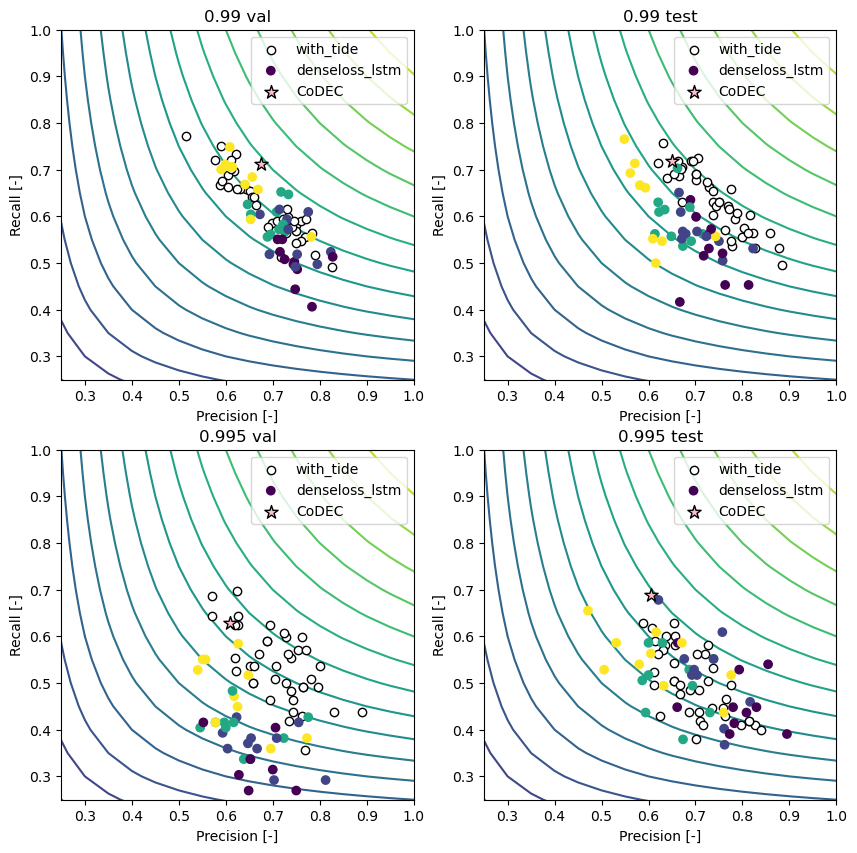

In [11]:
fig = plt.figure(figsize=(10,10))
quantile=.99
split='val'
ax = fig.add_subplot(221)
'''
ax.scatter(datasets[2].precision.sel(split=split,quantile=quantile).isel(tg=0),
            datasets[2].recall.sel(split=split,quantile=quantile).isel(tg=0),facecolor='red',edgecolor='black',label=labels[2])
'''
ax.scatter(datasets[1].precision.sel(split=split,quantile=quantile).isel(tg=0),
            datasets[1].recall.sel(split=split,quantile=quantile).isel(tg=0),facecolor='white',edgecolor='black',label=labels[1])

ax.scatter(datasets[0].precision.sel(split=split,quantile=quantile).isel(tg=0),
            datasets[0].recall.sel(split=split,quantile=quantile).isel(tg=0),c=datasets[0].hyperparameters.sel(split=split).isel(tg=0).sel(p='dl_alpha'),label=labels[0])

ax.scatter(codec.precision.sel(split=split,quantile=quantile,tg='esbjerg-esb-dnk-dmi.csv'),
                                      codec.recall.sel(split=split,quantile=quantile,tg='esbjerg-esb-dnk-dmi.csv'),marker='*',facecolor='pink',edgecolor='black',s=100,label='CoDEC')
ax.contour(P,R,f1_contours,levels=20,zorder=0)
ax.set_title(str(quantile) +' '+str(split))
ax.set_xlabel('Precision [-]')
ax.set_ylabel('Recall [-]')
ax.set_xlim([.25,1])
ax.set_ylim([.25,1])
ax.legend()


quantile=.99
split='test'
ax = fig.add_subplot(222)
'''
ax.scatter(datasets[2].precision.sel(split=split,quantile=quantile).isel(tg=0),
            datasets[2].recall.sel(split=split,quantile=quantile).isel(tg=0),facecolor='red',edgecolor='black',label=labels[2])
'''
ax.scatter(datasets[1].precision.sel(split=split,quantile=quantile).isel(tg=0),
            datasets[1].recall.sel(split=split,quantile=quantile).isel(tg=0),facecolor='white',edgecolor='black',label=labels[1])

ax.scatter(datasets[0].precision.sel(split=split,quantile=quantile).isel(tg=0),
            datasets[0].recall.sel(split=split,quantile=quantile).isel(tg=0),c=datasets[0].hyperparameters.sel(split=split).isel(tg=0).sel(p='dl_alpha'),label=labels[0])
ax.scatter(codec.precision.sel(split=split,quantile=quantile,tg='esbjerg-esb-dnk-dmi.csv'),
                                      codec.recall.sel(split=split,quantile=quantile,tg='esbjerg-esb-dnk-dmi.csv'),marker='*',facecolor='pink',edgecolor='black',s=100,label='CoDEC')
ax.contour(P,R,f1_contours,levels=20,zorder=0)
ax.set_title(str(quantile) +' '+str(split))
ax.set_xlabel('Precision [-]')
ax.set_ylabel('Recall [-]')
ax.set_xlim([.25,1])
ax.set_ylim([.25,1])
ax.legend()


quantile=.995
split='val'
ax = fig.add_subplot(223)
'''
ax.scatter(datasets[2].precision.sel(split=split,quantile=quantile).isel(tg=0),
            datasets[2].recall.sel(split=split,quantile=quantile).isel(tg=0),facecolor='red',edgecolor='black',label=labels[2])
'''
ax.scatter(datasets[1].precision.sel(split=split,quantile=quantile).isel(tg=0),
            datasets[1].recall.sel(split=split,quantile=quantile).isel(tg=0),facecolor='white',edgecolor='black',label=labels[1])

ax.scatter(datasets[0].precision.sel(split=split,quantile=quantile).isel(tg=0),
            datasets[0].recall.sel(split=split,quantile=quantile).isel(tg=0),c=datasets[0].hyperparameters.sel(split=split).isel(tg=0).sel(p='dl_alpha'),label=labels[0])
ax.scatter(codec.precision.sel(split=split,quantile=quantile,tg='esbjerg-esb-dnk-dmi.csv'),
                                      codec.recall.sel(split=split,quantile=quantile,tg='esbjerg-esb-dnk-dmi.csv'),marker='*',facecolor='pink',edgecolor='black',s=100,label='CoDEC')
ax.contour(P,R,f1_contours,levels=20,zorder=0)
ax.set_title(str(quantile) +' '+str(split))
ax.set_xlabel('Precision [-]')
ax.set_ylabel('Recall [-]')
ax.set_xlim([.25,1])
ax.set_ylim([.25,1])
ax.legend()


quantile=.995
split='test'
ax = fig.add_subplot(224)
'''
ax.scatter(datasets[2].precision.sel(split=split,quantile=quantile).isel(tg=0),
            datasets[2].recall.sel(split=split,quantile=quantile).isel(tg=0),facecolor='red',edgecolor='black',label=labels[2])
'''
ax.scatter(datasets[1].precision.sel(split=split,quantile=quantile).isel(tg=0),
            datasets[1].recall.sel(split=split,quantile=quantile).isel(tg=0),facecolor='white',edgecolor='black',label=labels[1])

ax.scatter(datasets[0].precision.sel(split=split,quantile=quantile).isel(tg=0),
            datasets[0].recall.sel(split=split,quantile=quantile).isel(tg=0),c=datasets[0].hyperparameters.sel(split=split).isel(tg=0).sel(p='dl_alpha'),label=labels[0])
ax.scatter(codec.precision.sel(split=split,quantile=quantile,tg='esbjerg-esb-dnk-dmi.csv'),
                                      codec.recall.sel(split=split,quantile=quantile,tg='esbjerg-esb-dnk-dmi.csv'),marker='*',facecolor='pink',edgecolor='black',s=100,label='CoDEC')
ax.contour(P,R,f1_contours,levels=20,zorder=0)
ax.set_title(str(quantile) +' '+str(split))
ax.set_xlabel('Precision [-]')
ax.set_ylabel('Recall [-]')
ax.set_xlim([.25,1])
ax.set_ylim([.25,1])
ax.legend()